Dados de vendas e classificações de jogos de videogame extraídos do VzCharts

In [1]:
# Libs Necessárias

# Libs para Modelagem e Matrizez
import numpy as np
import pandas as pd

# Libs para anaálises gráficas
import matplotlib.pyplot as plt
import seaborn as sns

# Lib para ignorar avisos
import warnings

# Desabilitando avisos
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv ('PS4_GamesSales.csv', encoding='latin-1')
df.head(3)

,Game,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94


In [3]:
df.shape

(1034, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1034 entries, 0 to 1033
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Game           1034 non-null   object 
 1   Year           825 non-null    float64
 2   Genre          1034 non-null   object 
 3   Publisher      825 non-null    object 
 4   North America  1034 non-null   float64
 5   Europe         1034 non-null   float64
 6   Japan          1034 non-null   float64
 7   Rest of World  1034 non-null   float64
 8   Global         1034 non-null   float64
dtypes: float64(6), object(3)
memory usage: 72.8+ KB


In [5]:
list_columns = df.columns
list_trad = ['Jogo', 'Ano', 'Gênero', 'Produtora', 'América do Norte', 'Europa',
'Japão', 'Resto do mundo', 'Global']
new_columns = {}
for old, new in zip(list_columns, list_trad):
    new_columns[old]=new

In [6]:
df = df.rename(columns=new_columns)
df

,Jogo,Ano,Gênero,Produtora,América do Norte,Europa,Japão,Resto do mundo,Global
0,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80
...,...,...,...,...,...,...,...,...,...
1029,Fallen Legion: Flames of Rebellion,NaN,Role-Playing,NaN,0.00,0.00,0.00,0.00,0.00
1030,Radial G Racing Revolved,2017.0,Racing,Tammeka Games,0.00,0.00,0.00,0.00,0.00
1031,The Mummy Demastered,NaN,Action,NaN,0.00,0.00,0.00,0.00,0.00
1032,Project Nimbus: Code Mirai,NaN,Action,NaN,0.00,0.00,0.00,0.00,0.00


In [7]:
df.isnull().sum()

Jogo                  0
Ano                 209
Gênero                0
Produtora           209
América do Norte      0
Europa                0
Japão                 0
Resto do mundo        0
Global                0
dtype: int64

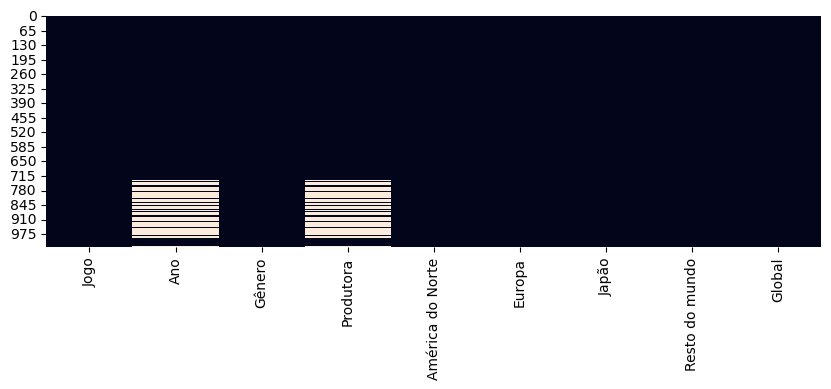

In [8]:
plt.figure(figsize=(10,3))
sns.heatmap(df.isnull(), cbar=False);

In [9]:
df.dropna(inplace=True)

In [10]:
df.describe()

,Ano,América do Norte,Europa,Japão,Resto do mundo,Global
count,825.000000,825.000000,825.000000,825.000000,825.000000,825.000000
mean,2015.966061,0.256448,0.311600,0.042048,0.111552,0.721721
std,1.298360,0.620259,0.868271,0.119814,0.274713,1.743122
min,2013.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.000000,0.000000,0.000000,0.000000,0.000000,0.030000
50%,2016.000000,0.050000,0.020000,0.000000,0.020000,0.120000
75%,2017.000000,0.190000,0.220000,0.040000,0.090000,0.560000
max,2020.000000,6.180000,9.710000,2.170000,3.020000,19.390000


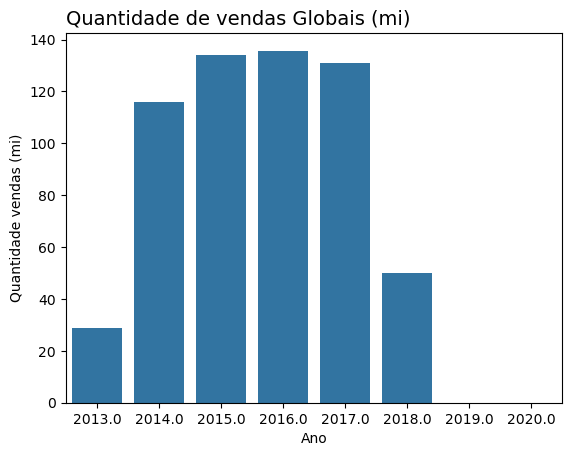

In [11]:
plt.title('Quantidade de vendas Globais (mi)', loc='left', fontsize=14)

sns.barplot(data=df, x='Ano', y='Global', ci=None, estimator=sum )
plt.ylabel('Quantidade vendas (mi)');

In [12]:
#Retirar os anos
df = df.loc[(df['Ano'] != 2019) & (df['Ano'] != 2020)]
df.head()

,Jogo,Ano,Gênero,Produtora,América do Norte,Europa,Japão,Resto do mundo,Global
0,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80


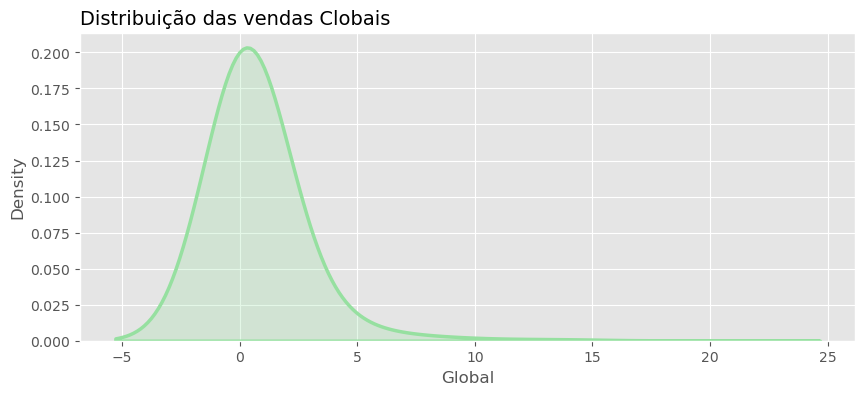

In [13]:
plt.figure(figsize=(10,4))
plt.style.use('ggplot')
plt.title('Distribuição das vendas Clobais', loc='left', fontsize=14)
sns.kdeplot(df['Global'], fill=True, bw=1, color='#96e0a0', linewidth=2.5 );

In [14]:
df.groupby(by=['Ano']).sum()

,Jogo,Gênero,Produtora,América do Norte,Europa,Japão,Resto do mundo,Global
Ano,,,,,,,,
2013.0,Call of Duty: GhostsBattlefield 4FIFA Soccer 1...,ShooterShooterSportsAction-AdventureShooterRac...,ActivisionElectronic ArtsEA SportsUbisoftSony ...,10.35,12.88,0.97,4.57,28.76
2014.0,Grand Theft Auto VCall of Duty: Advanced Warfa...,ActionShooterAction-AdventureMiscSportsShooter...,Rockstar GamesActivisionSony Computer Entertai...,39.80,54.12,3.58,18.29,115.85
2015.0,Call of Duty: Black Ops 3Fallout 4FIFA 16Star ...,ShooterRole-PlayingSportsShooterActionRole-Pla...,ActivisionBethesda SoftworksEA SportsElectroni...,49.60,56.21,7.28,20.88,133.99
2016.0,FIFA 17Uncharted (PS4)Call of Duty: Infinite W...,SportsActionShooterShooterRole-PlayingShooterS...,Electronic ArtsSony Interactive EntertainmentA...,47.40,57.98,9.65,20.71,135.72
2017.0,Call of Duty: WWIIFIFA 18Horizon: Zero DawnCra...,ShooterSportsActionPlatformShooterShooterActio...,ActivisionEA SportsSony Interactive Entertainm...,44.77,57.18,9.08,19.89,130.90
2018.0,Red Dead Redemption 2Spider-Man (PS4)God of Wa...,Action-AdventureAction-AdventureActionActionAc...,Rockstar GamesSony Interactive EntertainmentSo...,19.65,18.70,4.13,7.69,50.20


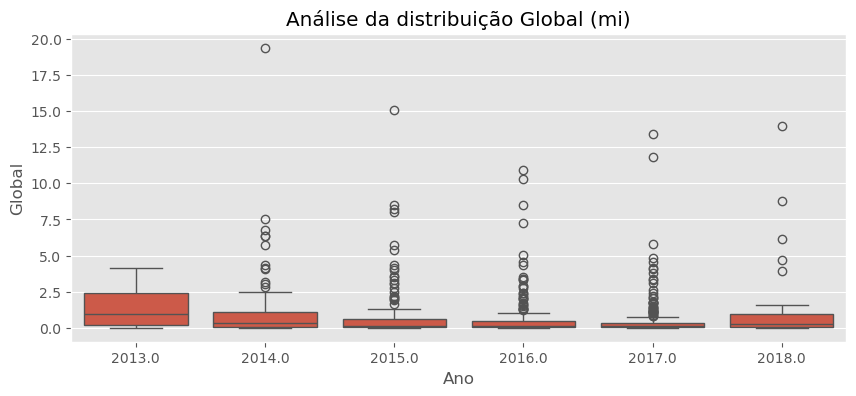

In [15]:
plt.figure(figsize=(10,4))
plt.title('Análise da distribuição Global (mi)')
sns.boxplot(data=df, x='Ano', y = 'Global');

In [16]:
df.loc[df['Global'] >= 10]

,Jogo,Ano,Gênero,Produtora,América do Norte,Europa,Japão,Resto do mundo,Global
0,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80
5,FIFA 17,2016.0,Sports,Electronic Arts,1.26,7.95,0.12,1.61,10.94
6,Uncharted (PS4),2016.0,Action,Sony Interactive Entertainment,4.49,3.93,0.21,1.70,10.33


In [17]:
analise = df.groupby(by=['Ano']).sum().reset_index()

In [18]:
americas = [americas / total * 100 for americas, total in zip (analise['América do Norte'], analise['Global'])]
europa = [europa / total *100 for europa, total in zip(analise['Europa'], analise['Global'])]
japao = [japao / total * 100 for japao, total in zip(analise['Japão'], analise['Global'])]
mundo = [mundo / total * 100 for mundo, total in zip(analise['Resto do mundo'], analise['Global'])]

americas, europa, japao, mundo

([35.9874826147427,
  34.35476909797151,
  37.01768788715576,
  34.92484526967286,
  34.20168067226891,
  39.14342629482071],
 [44.78442280945759,
  46.71558049201555,
  41.95089185760131,
  42.72030651340996,
  43.68220015278838,
  37.25099601593625],
 [3.372739916550765,
  3.0902028485110056,
  5.433241286663184,
  7.110226937813145,
  6.936592818945759,
  8.227091633466136],
 [15.890125173852576,
  15.78765645230902,
  15.58325248152847,
  15.259357500736812,
  15.194805194805195,
  15.31872509960159])

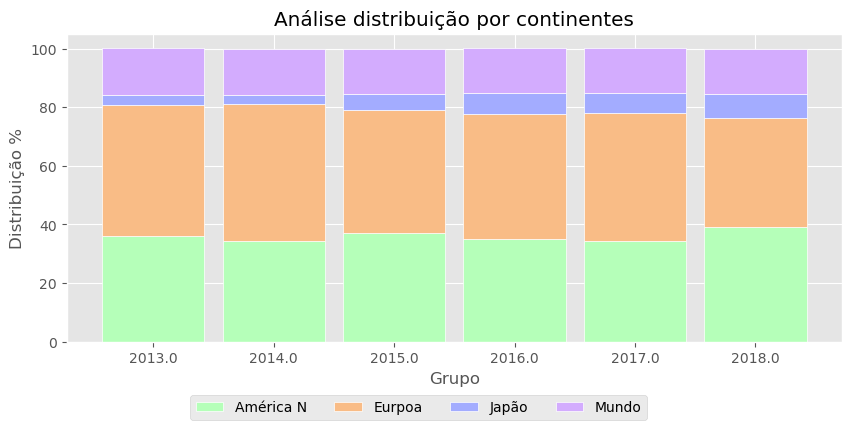

In [19]:
plt.figure(figsize=(10,4))

largura_barra = 0.85
rotulos = analise['Ano']
grupos = [0,1,2,3,4,5]

plt.bar(grupos, americas, width=largura_barra, color='#b5ffb9', edgecolor= 'white')
plt.bar(grupos, europa, bottom=americas, width=largura_barra, color='#f9bc86', edgecolor='white')
plt.bar(grupos, japao, bottom=[(A + B) for A, B in zip(americas, europa)], width=largura_barra, color='#a3acff', edgecolor='white')
plt.bar(grupos, mundo, bottom=[(A + B + C) for A, B, C in zip(americas, europa, japao)], width=largura_barra, color='#d3acfe', edgecolor='white')
plt.title('Análise distribuição por continentes')
plt.xticks(grupos, rotulos)
plt.xlabel('Grupo')
plt.ylabel('Distribuição %')
plt.legend(['América N', 'Eurpoa', 'Japão', 'Mundo'], loc='upper left', bbox_to_anchor=(0.15, -0.15), ncol=4);

In [20]:
df['Produtora'].unique()

array(['Rockstar Games', 'Activision', 'EA Sports', 'Electronic Arts',
       'Sony Interactive Entertainment', 'Bethesda Softworks',
       'Sony Computer Entertainment', 'Namco Bandai Games', 'Square Enix',
       'Capcom', 'Blizzard Entertainment', 'Ubisoft',
       'Warner Bros. Interactive', '2K Sports',
       'Warner Bros. Interactive Entertainment',
       'Konami Digital Entertainment', '2K Games', 'Hello Games',
       '505 Games', 'Deep Silver', 'Take-Two Interactive',
       'Bandai Namco Games', 'Sega', 'Tecmo Koei', 'Gearbox Software',
       'Mojang', 'Disney Interactive Studios', 'Focus Home Interactive',
       'Studio Wildcard', 'Codemasters', 'Koch Media',
       'Harmonix Music Systems', 'Rebellion Developments', 'Gun Media',
       'Telltale Games', 'Kalypso Media', 'City Interactive',
       'NIS America', 'Sold Out', 'Tripwire Interactive', 'PQube',
       'THQ Nordic', 'Milestone S.r.l.', 'Nordic Games', 'Astragon',
       'Koei Tecmo', 'Frontier Developments', 

In [ ]:
from sklearn.preprocessing import LabelEncoder #Transforma valores qualitativos para quantitativos

In [25]:
funcao_label = LabelEncoder()
df['Produtor'] = funcao_label.fit_transform(df['Produtora'])
df['Genre'] = funcao_label.fit_transform(df['Gênero'])
df['Game'] = funcao_label.fit_transform(df['Jogo'])
df.head(3)


,Jogo,Ano,Gênero,Produtora,América do Norte,Europa,Japão,Resto do mundo,Global,Produtor,Genre,Game
0,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39,107,0,273
1,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09,8,12,98
2,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94,107,1,521


In [26]:
paleta_cores = sns.color_palette('husl', 8)
paleta_cores

[(0.9677975592919913, 0.44127456009157356, 0.5358103155058701),
 (0.8087954113106306, 0.5634700050056693, 0.19502642696727285),
 (0.5920891529639701, 0.6418467016378244, 0.1935069134991043),
 (0.19783576093349015, 0.6955516966063037, 0.3995301037444499),
 (0.21044753832183283, 0.6773105080456748, 0.6433941168468681),
 (0.22335772267769388, 0.6565792317435265, 0.8171355503265633),
 (0.6423044349219739, 0.5497680051256467, 0.9582651433656727),
 (0.96038885399407, 0.3814317878772117, 0.8683117650835491)]

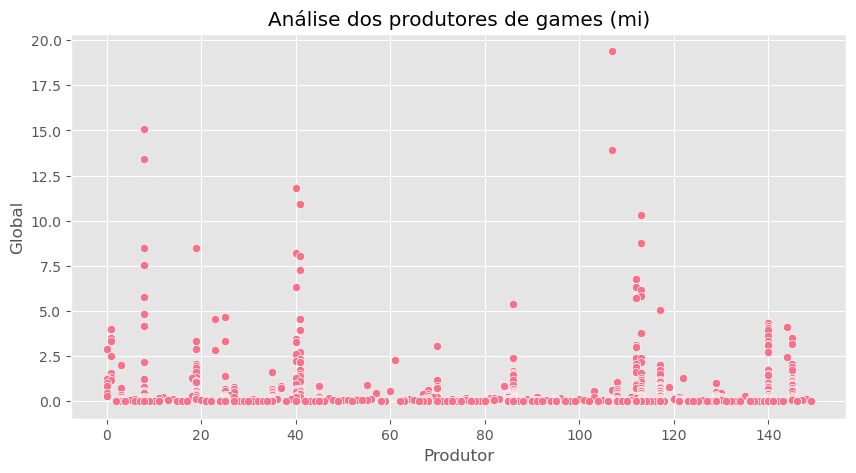

In [28]:
plt.figure(figsize=(10,5))
plt.title('Análise dos produtores de games (mi)')
sns.scatterplot(data=df, x='Produtor', y = 'Global', color= paleta_cores[0]);

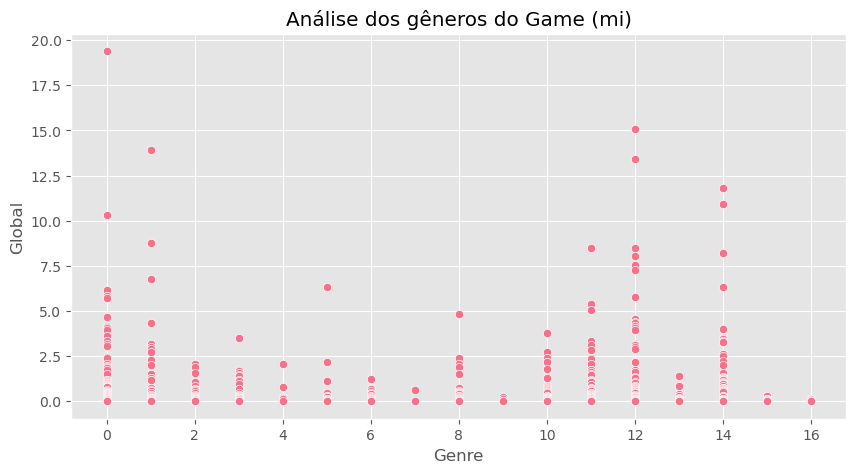

In [30]:
plt.figure(figsize=(10,5))
plt.title('Análise dos gêneros do Game (mi)')
sns.scatterplot(data=df, x='Genre', y = 'Global', color=paleta_cores[0]);

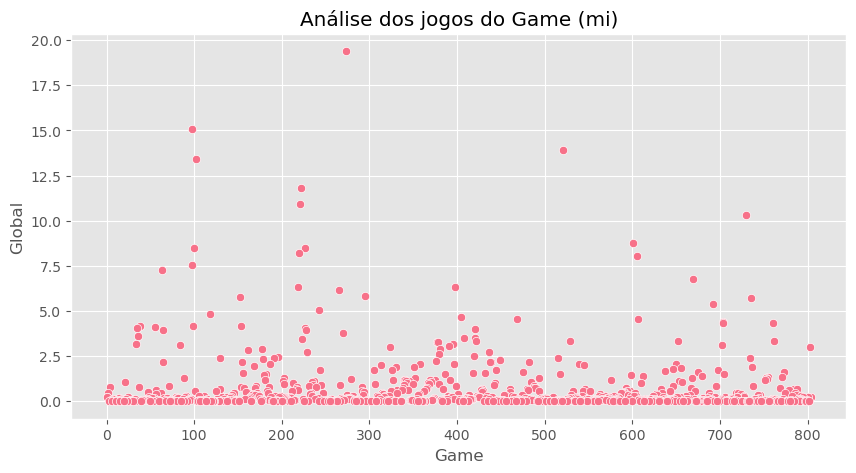

In [31]:
plt.figure(figsize=(10,5))
plt.title('Análise dos jogos do Game (mi)')
sns.scatterplot(data=df, x='Game', y = 'Global', color=paleta_cores[0]);

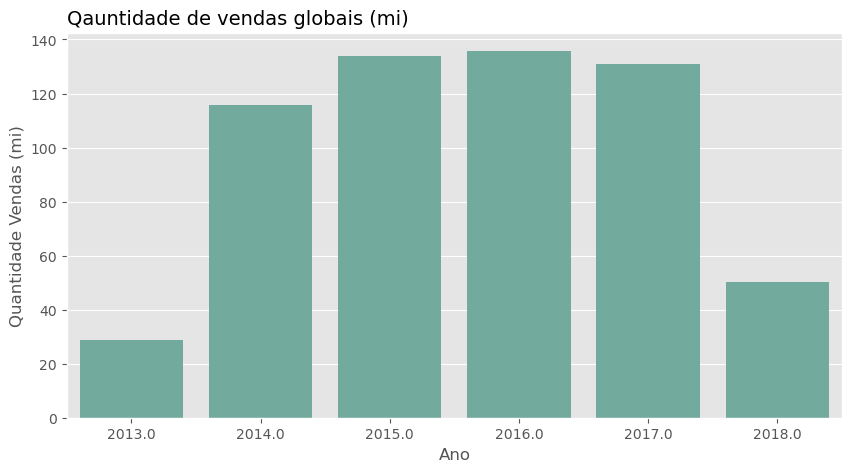

In [32]:
plt.figure(figsize=(10,5))
plt.title('Qauntidade de vendas globais (mi)', loc='left', fontsize=14)
sns.barplot(data=df, x='Ano', y = 'Global', ci=None, color='#69b3a2', estimator=sum)
plt.ylabel('Quantidade Vendas (mi)');